<a href="https://colab.research.google.com/github/dominicbarasa/Artificial-Intelligence-/blob/main/Week_10_Assignment_Model_Evaluation_Concrete_Strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Week 10 Assignment: Evaluating and Preparing Your ML Model for Use

**Name:** Dominic Barasa

**Course:** AI for Science and Engineering

**Project:** Prediction of Concrete Compressive Strength Using Machine Learning

## Project Introduction

The objective of this project is to evaluate and prepare a machine learning model developed to predict concrete compressive strength using concrete mix ingredients and curing age.

The project uses Linear Regression and Random Forest Regression models. This assignment focuses on model evaluation, overfitting and underfitting, feature importance, saving and loading the trained model, and making predictions using new concrete mix data.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

url = "https://raw.githubusercontent.com/HansenHan/ML_UCI_Concrete_Compressive_Strength/main/Concrete_Data.csv"

df = pd.read_csv(url)

df.columns = [
    "Cement",
    "Blast_Furnace_Slag",
    "Fly_Ash",
    "Water",
    "Superplasticizer",
    "Coarse_Aggregate",
    "Fine_Aggregate",
    "Age",
    "Compressive_Strength"
]

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1030, 9)


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:

X = df.drop("Compressive_Strength", axis=1)
y = df["Compressive_Strength"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:")
print(X.columns.tolist())


Features shape: (1030, 8)
Target shape: (1030,)
Feature names:
['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer', 'Coarse_Aggregate', 'Fine_Aggregate', 'Age']


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 824
Testing samples: 206


In [6]:

# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Random Forest Regression
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Both models have been trained successfully.")


Both models have been trained successfully.


In [7]:
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Make predictions on test data
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Evaluate both models
linear_results = evaluate_model(y_test, linear_predictions)
rf_results = evaluate_model(y_test, rf_predictions)

# Display comparison
results = pd.DataFrame(
    [linear_results, rf_results],
    index=["Linear Regression", "Random Forest"]
)

display(results.round(3))

,MAE,MSE,RMSE,R2 Score
Linear Regression,7.746,95.971,9.796,0.628
Random Forest,3.736,29.854,5.464,0.884


### Interpretation of Model Evaluation Results

The Random Forest Regression model performed better than Linear Regression in predicting concrete compressive strength.

Random Forest achieved an MAE of 3.736 MPa, RMSE of 5.464 MPa and R² score of 0.884. Linear Regression achieved an MAE of 7.746 MPa, RMSE of 9.796 MPa and R² score of 0.628.

The results indicate that Random Forest provides more accurate predictions and explains approximately 88.4% of the variation in concrete compressive strength. Therefore, Random Forest was selected as the best-performing model for this project.

In [8]:
# Predictions on training data
linear_train_predictions = linear_model.predict(X_train)
rf_train_predictions = random_forest_model.predict(X_train)

# Evaluate training performance
linear_train_results = evaluate_model(y_train, linear_train_predictions)
rf_train_results = evaluate_model(y_train, rf_train_predictions)

# Create comparison table
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Training RMSE": [
        linear_train_results["RMSE"],
        rf_train_results["RMSE"]
    ],
    "Testing RMSE": [
        linear_results["RMSE"],
        rf_results["RMSE"]
    ],
    "Training R2": [
        linear_train_results["R2 Score"],
        rf_train_results["R2 Score"]
    ],
    "Testing R2": [
        linear_results["R2 Score"],
        rf_results["R2 Score"]
    ]
})

display(comparison.round(3))

,Model,Training RMSE,Testing RMSE,Training R2,Testing R2
0,Linear Regression,10.519,9.796,0.611,0.628
1,Random Forest,1.983,5.464,0.986,0.884


### Training and Testing Performance Interpretation

The Random Forest model achieved a training RMSE of 1.983 MPa and a testing RMSE of 5.464 MPa. Its training R² score was 0.986, while its testing R² score was 0.884.

The difference between training and testing performance indicates some evidence of overfitting. This means the model learned the training data very well but performed slightly less accurately on unseen data.

However, the testing R² score of 0.884 indicates that the model still generalizes reasonably well and explains approximately 88.4% of the variation in concrete compressive strength.

Linear Regression showed more consistent training and testing performance but had lower predictive accuracy.

Therefore, Random Forest remains the preferred model for this project, although further tuning could help reduce overfitting.

In [9]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# Calculate feature importance
importance = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

# Create importance table
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
})

# Arrange from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
7,Age,9.9814
0,Cement,7.4319
3,Water,3.5697
1,Blast_Furnace_Slag,3.2563
4,Superplasticizer,1.6336
6,Fine_Aggregate,0.7897
5,Coarse_Aggregate,0.2165
2,Fly_Ash,0.0911


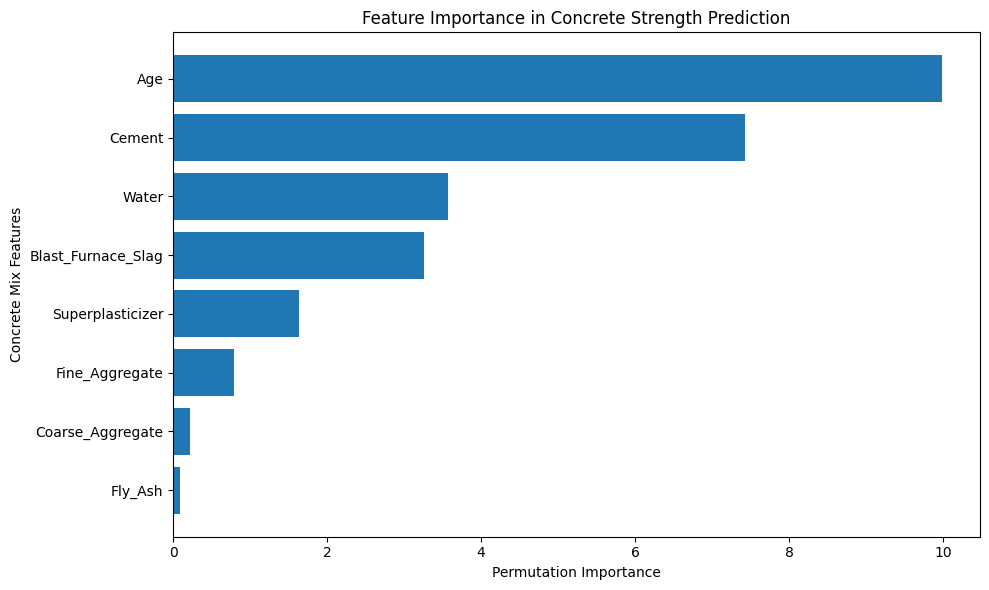

In [10]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Concrete Mix Features")
plt.title("Feature Importance in Concrete Strength Prediction")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Interpretation of Feature Importance

The feature-importance analysis shows that Age was the most influential feature in predicting concrete compressive strength, followed by Cement content. Water and Blast Furnace Slag also had considerable influence on the model's predictions.

Superplasticizer, Fine Aggregate and Coarse Aggregate had lower importance, while Fly Ash had the lowest importance in this analysis.

From an engineering perspective, the results highlight the importance of curing age and cement content when estimating concrete strength. However, all mix ingredients should be considered during concrete production because their combined proportions influence concrete performance.

Feature importance shows the contribution of each variable to the model's predictive performance; it does not establish a direct cause-and-effect relationship.

In [1]:
import joblib

# Select the best-performing model
best_model = random_forest_model

# Save the trained model
joblib.dump(best_model, "concrete_strength_model.pkl")

# Load the saved model
loaded_model = joblib.load("concrete_strength_model.pkl")

print("Random Forest model saved and loaded successfully.")

NameError: name 'random_forest_model' is not defined